In [5]:
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
import numpy as np
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms.gradients import ParamShiftEstimatorGradient

# Create a circuit with a register of three qubits change this to actual A later

# beginning dimension
m_0 = 8 # of variables
v_0 = np.random.rand(m_0)
v_0_norm = np.linalg.norm(v_0)
n_0 = int(np.ceil(np.log2(m_0)))
print(n_0)
A = np.eye(2**(n_0*3))


# not sure how to implement this into actual circuit
# quantum jacobian?

#subset of parameters used in dimension matching requirement (this would have to be given earlier as it changes)
params = [] 
# Define the estimator
estimator = StatevectorEstimator(seed=42)
# Define the gradient
gradient = ParamShiftEstimatorGradient(estimator)

# Evaluate the gradient of the circuits using parameter shift gradients
pse_grad_result = gradient.run(qc, H, params).result().gradients

# acceptance ratio
alpha = 0.0

3


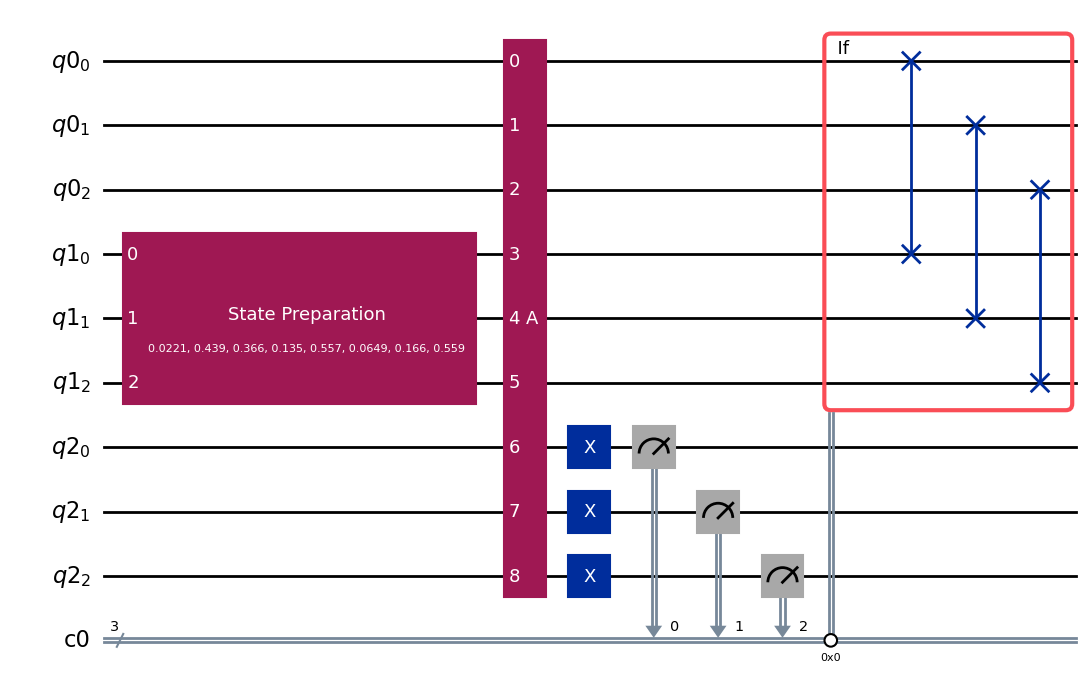

In [6]:
qreg_prev = QuantumRegister(n_0)
qreg_next = QuantumRegister(n_0)
creg = ClassicalRegister(n_0)
qreg_a = QuantumRegister(n_0)

circ = QuantumCircuit(creg,qreg_prev,qreg_next,qreg_a)
circ.prepare_state(v_0/v_0_norm,qubits=qreg_next)
A=UnitaryGate(A, label='A')
circ.append(A, range(n_0*3))
circ.x(qreg_a)
circ.measure(qreg_a,creg)
with circ.if_test((creg,0)):
    circ.swap(qreg_prev,qreg_next)
# Draw the circuit
circ.draw('mpl')
#circ.decompose(reps=5).draw('mpl')

# understand TD vs. RJ
# draw the decomposed circuit to assess the complexity of state_preparation for large inputs (done)
# figure out the information that we are going to simulate (parameters)